# EE 513: Assignment 3

Alexander Matteson

DUE: 10/20/2026

GitHub Link: https://github.com/AlexanderMatteson/Matteson_ee513_project1

In [29]:
# imports:
import rawpy
import imageio.v3 as iio
import os
import rawpy
from fractions import Fraction
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2
from matplotlib.colors import ListedColormap
import sys
from scipy.optimize import brentq
from scipy.special import erf
import matplotlib
import psu_imaging as psu
import sys
from pathlib import Path

from pathlib import Path
import exifread
import math

### Catpures:

1. Capture at least ten pairs of flat fields spanning the range from nearly black to nearly saturated, two frames at each level with nothing moved or changed between them.
Deliverable: A contact sheet showing one frame from each pair, and a list giving the exposure time and ISO of every capture.

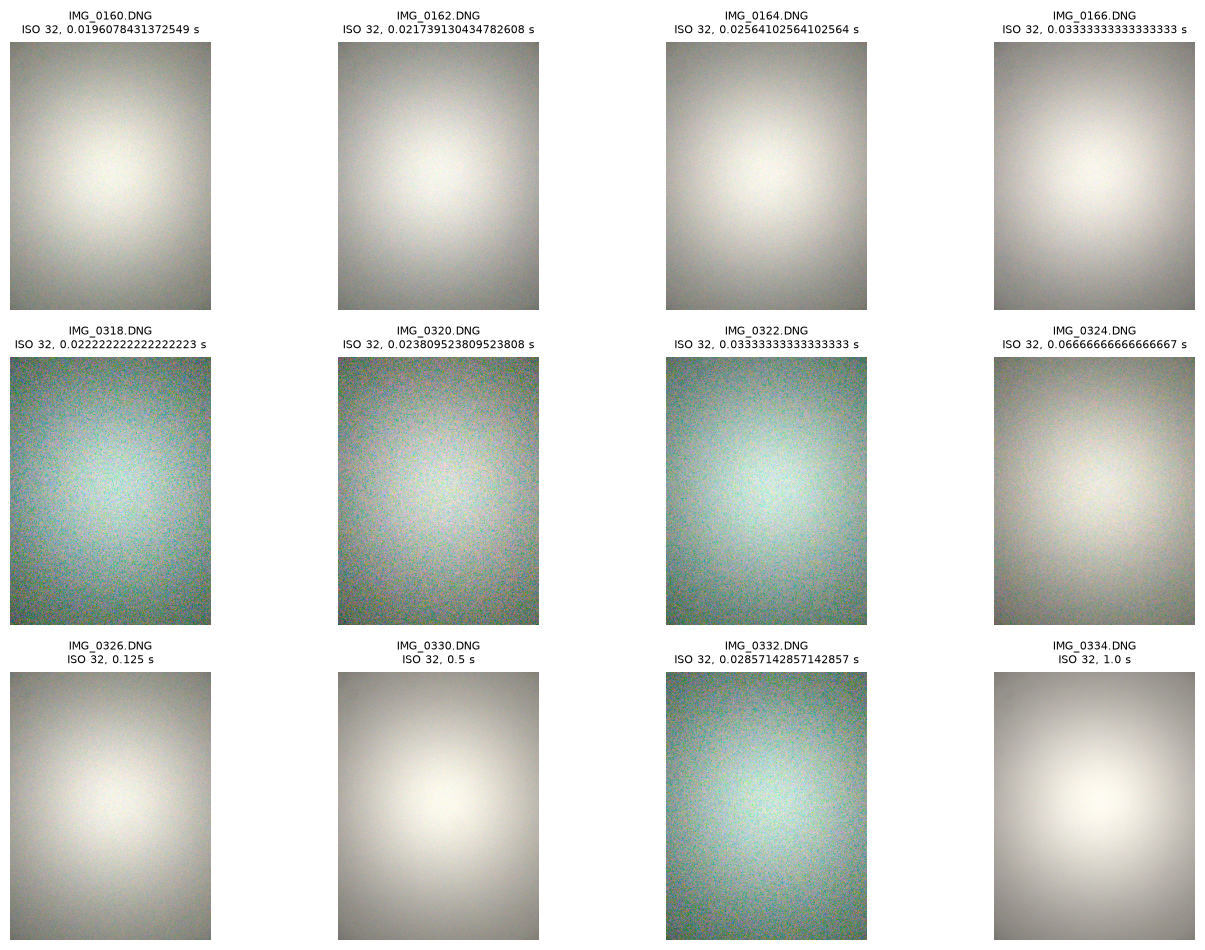

In [2]:
FOLDER = r"C:\Users\ammat\Documents\Assigmnet3 Captures\old"
def get_exposure_iso(path):
    """Return (exposure_seconds, iso) for one DNG. Missing values come back as None."""
    with open(path, "rb") as f:
        tags = exifread.process_file(f, details=False)

    exp = tags.get("EXIF ExposureTime")
    exposure = float(exp.values[0].num) / float(exp.values[0].den) if exp else None

    iso_tag = tags.get("EXIF ISOSpeedRatings") or tags.get("EXIF PhotographicSensitivity")
    iso = int(iso_tag.values[0]) if iso_tag else None

    return exposure, iso
def show_contact_sheet(folder, step=2, cols=4, thumb_size=300, recursive=False):
    """Display a contact sheet of every `step`-th DNG in a folder."""
    pattern = "**/*" if recursive else "*"
    files = sorted(p for p in Path(folder).glob(pattern) if p.suffix.lower() == ".dng")
    files = files[::step]  # every other file (0, 2, 4, ...)

    if not files:
        print("No DNG files found.")
        return

    rows = math.ceil(len(files) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 3.2), squeeze=False)

    for ax in axes.flat:
        ax.axis("off")

    for ax, p in zip(axes.flat, files):
        with rawpy.imread(str(p)) as raw:
            # half_size skips demosaicing detail for speed; fine for thumbnails
            img = raw.postprocess(half_size=True, use_camera_wb=True, output_bps=8)

        # Shrink so the longest side is thumb_size px
        scale = max(1, max(img.shape[:2]) // thumb_size)
        ax.imshow(img[::scale, ::scale])

        exposure, iso = get_exposure_iso(p)
        ax.set_title(f"{p.name}\nISO {iso}, {exposure} s", fontsize=8)

    plt.tight_layout()
    plt.show()

show_contact_sheet(FOLDER)

In [3]:
# Create list of captures and exposre + ISO values:

def get_exposure_iso(path):
    """Return (exposure_seconds, iso) for one DNG. Missing values come back as None."""
    with open(path, "rb") as f:
        tags = exifread.process_file(f, details=False)

    exp = tags.get("EXIF ExposureTime")
    exposure = float(exp.values[0].num) / float(exp.values[0].den) if exp else None

    iso_tag = tags.get("EXIF ISOSpeedRatings") or tags.get("EXIF PhotographicSensitivity")
    iso = int(iso_tag.values[0]) if iso_tag else None

    return exposure, iso


def print_dng_settings(folder, recursive=False):
    """Print filename, ISO, and exposure for every DNG in a folder."""
    pattern = "**/*" if recursive else "*"
    files = sorted(p for p in Path(folder).glob(pattern) if p.suffix.lower() == ".dng")

    results = {}
    for p in files:
        exposure, iso = get_exposure_iso(p)
        results[p.name] = (exposure, iso)
        print(f"{p.name:<30} ISO: {iso}   Exposure: {exposure} s")
    return results

settings = print_dng_settings(FOLDER)

IMG_0160.DNG                   ISO: 32   Exposure: 0.0196078431372549 s
IMG_0161.DNG                   ISO: 32   Exposure: 0.0196078431372549 s
IMG_0162.DNG                   ISO: 32   Exposure: 0.021739130434782608 s
IMG_0163.DNG                   ISO: 32   Exposure: 0.021739130434782608 s
IMG_0164.DNG                   ISO: 32   Exposure: 0.02564102564102564 s
IMG_0165.DNG                   ISO: 32   Exposure: 0.02564102564102564 s
IMG_0166.DNG                   ISO: 32   Exposure: 0.03333333333333333 s
IMG_0167.DNG                   ISO: 32   Exposure: 0.03333333333333333 s
IMG_0318.DNG                   ISO: 32   Exposure: 0.022222222222222223 s
IMG_0319.DNG                   ISO: 32   Exposure: 0.022222222222222223 s
IMG_0320.DNG                   ISO: 32   Exposure: 0.023809523809523808 s
IMG_0321.DNG                   ISO: 32   Exposure: 0.023809523809523808 s
IMG_0322.DNG                   ISO: 32   Exposure: 0.03333333333333333 s
IMG_0323.DNG                   ISO: 32   Exposu

Hmm good we checked this, why are some of the repeats of hte longer exposrues incorrect. I'm going to try to re do those longer exposure captures. -> I switched the raw app and redid all captures and exposure pairs.

2. Confirm from the metadata that the entire series came from one camera at one ISO, using the lens_id helper from the Project 1 page together with the ISO field. Deliverable: The assertion passing, or an account of which captures differ and what you did about it.

In [4]:
# I think this is what you mean:
import tifffile
from glob import glob

def lens_id(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = p.tags["ExifTag"].value
        fl = exif["FocalLength"]
        return (exif.get("LensModel", "unknown"),
                round(fl[0] / fl[1], 3),
                exif.get("FocalLengthIn35mmFilm"),
                (p.tags["ImageWidth"].value, p.tags["ImageLength"].value))


FOLDER = r"C:\Users\ammat\OneDrive\Documents\ee513\Images"
my_capture_series = [os.path.join(FOLDER, f"Edge{i}.dng") for i in range(1, 6)]

ids = {lens_id(f) for f in my_capture_series}
assert len(ids) == 1, f"more than one camera in this series: {ids}"

Using the code from project 1 it passes. And from the print out above all images have ISO = 64 and th pairs of exposures match.

3. Capture five dark frames with the lens covered at each of four exposure times, spanning the longest range your app allows, and compare their level against the black level recorded in the file.
Deliverable: The black level per channel from the file, the mean of your shortest dark frames in digital numbers, and one sentence on whether the two agree.

Load the contact sheet of these frames:

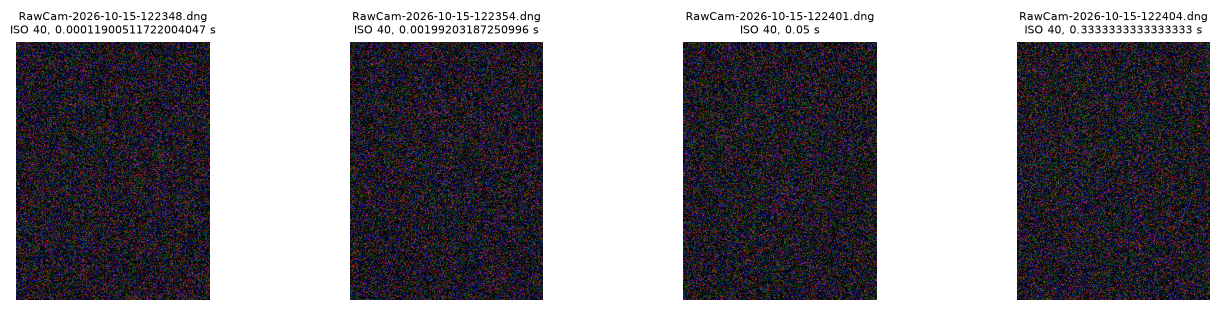

In [5]:
FOLDER = r"C:\Users\ammat\Documents\Assigmnet3 Captures\BlackFrame"
def show_contact_sheet(folder, step=1, cols=4, thumb_size=300, recursive=False):
    """Display a contact sheet of every `step`-th DNG in a folder."""
    pattern = "**/*" if recursive else "*"
    files = sorted(p for p in Path(folder).glob(pattern) if p.suffix.lower() == ".dng")
    files = files[::step]  # every other file (0, 2, 4, ...)

    if not files:
        print("No DNG files found.")
        return

    rows = math.ceil(len(files) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 3.2), squeeze=False)

    for ax in axes.flat:
        ax.axis("off")

    for ax, p in zip(axes.flat, files):
        with rawpy.imread(str(p)) as raw:
            # half_size skips demosaicing detail for speed; fine for thumbnails
            img = raw.postprocess(half_size=True, use_camera_wb=True, output_bps=8)

        # Shrink so the longest side is thumb_size px
        scale = max(1, max(img.shape[:2]) // thumb_size)
        ax.imshow(img[::scale, ::scale])

        exposure, iso = get_exposure_iso(p)
        ax.set_title(f"{p.name}\nISO {iso}, {exposure} s", fontsize=8)

    plt.tight_layout()
    plt.show()

show_contact_sheet(FOLDER)

In [6]:
def report_black_levels(folder, recursive=False):
    """Print the black level (per channel) and white level for every DNG in a folder."""
    pattern = "**/*" if recursive else "*"
    files = sorted(p for p in Path(folder).glob(pattern) if p.suffix.lower() == ".dng")

    results = {}
    for p in files:
        with rawpy.imread(str(p)) as raw:
            black = list(raw.black_level_per_channel)  # one value per CFA channel (e.g. R, G1, B, G2)
            white = raw.white_level
            pattern_str = "".join("RGBG"[i] if i < 4 else "?" for i in raw.raw_pattern.flatten()) \
                if raw.raw_pattern is not None else "n/a"

        results[p.name] = {"black_level": black, "white_level": white}
        print(f"{p.name:<30} black: {black}   white: {white}")
    return results

report_black_levels(FOLDER)

RawCam-2026-10-15-122348.dng   black: [528, 528, 528, 528]   white: 4095
RawCam-2026-10-15-122354.dng   black: [528, 528, 528, 528]   white: 4095
RawCam-2026-10-15-122401.dng   black: [528, 528, 528, 528]   white: 4095
RawCam-2026-10-15-122404.dng   black: [528, 528, 528, 528]   white: 4095


{'RawCam-2026-10-15-122348.dng': {'black_level': [528, 528, 528, 528],
  'white_level': 4095},
 'RawCam-2026-10-15-122354.dng': {'black_level': [528, 528, 528, 528],
  'white_level': 4095},
 'RawCam-2026-10-15-122401.dng': {'black_level': [528, 528, 528, 528],
  'white_level': 4095},
 'RawCam-2026-10-15-122404.dng': {'black_level': [528, 528, 528, 528],
  'white_level': 4095}}

In [7]:
def measure_dark_level(path):
    """Mean raw value per CFA channel; for a dark frame this approximates the black level."""
    with rawpy.imread(str(path)) as raw:
        data = raw.raw_image_visible.astype(float)
        colors = raw.raw_colors_visible
        return {int(c): data[colors == c].mean() for c in np.unique(colors)}
print("mean of each channel for 0.0001 s exposure: " + str(measure_dark_level(FOLDER + r"\RawCam-2026-10-15-122348.dng")))
print("mean of each channel for 0.0019 s exposure: " + str(measure_dark_level(FOLDER + r"\RawCam-2026-10-15-122354.dng")))
print("mean of each channel for 0.05 s exposure: " + str(measure_dark_level(FOLDER + r"\RawCam-2026-10-15-122401.dng")))
print("mean of each channel for 0.033 s exposure: " + str(measure_dark_level(FOLDER + r"\RawCam-2026-10-15-122404.dng")))


mean of each channel for 0.0001 s exposure: {0: np.float64(527.6841311177249), 1: np.float64(527.6619507563828), 2: np.float64(527.7980412651171), 3: np.float64(527.6628604759806)}
mean of each channel for 0.0019 s exposure: {0: np.float64(527.6739690281977), 1: np.float64(527.6528719319518), 2: np.float64(527.78811603731), 3: np.float64(527.6545207782187)}
mean of each channel for 0.05 s exposure: {0: np.float64(527.7867296417023), 1: np.float64(527.6900795619174), 2: np.float64(527.7712726101242), 3: np.float64(527.6885025615185)}
mean of each channel for 0.033 s exposure: {0: np.float64(527.8428675096582), 1: np.float64(527.7446574887671), 2: np.float64(527.8259640468842), 3: np.float64(527.7425729744058)}


See above for the file dark level (528 for all) an the measured dark levels from the captures. These are very close, all measuements are with in 0.5 ofhte file value. I was thinking maybe this was the result of noise (like dark current or shot noise?), but then I also realized if they are all with in 0.5 of the file value that could be the result of the arounding and precision that is reported, if they are all rounded up they all match.

### Part 2: The Photon Transfer Curve

4. Before fitting any of your own data, run your photon transfer code on the simulated sensor in the lecture 5 demo notebook, which reports the true gain and read noise it used to generate the frames.
Deliverable: Your recovered gain and read noise beside the true values, as percentage errors.

22 exposure levels, two frames each, 128 x 128 px


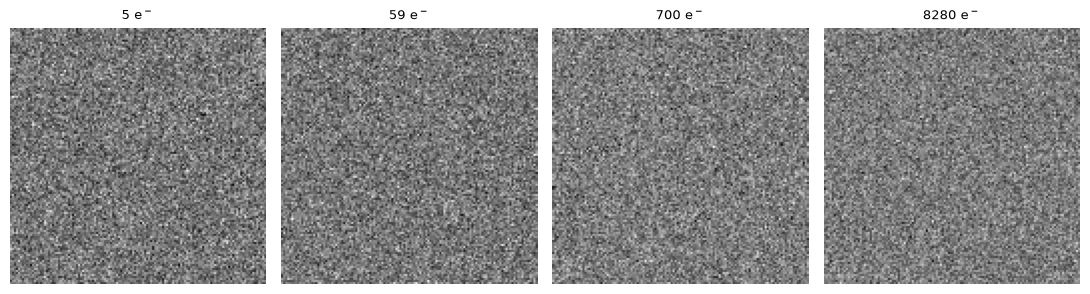

simulated pairs K = 0.4236 DN/e-
simulated pairs read noise = 2.9602 e-
truth                   K = 0.4266 DN/e-            read noise =  2.80 e-
K percent error: -0.6900710419780219%
read percent error: 5.721657632477197%


In [8]:
# Simulated sensor from lecture 5:

PRNU = 0.012          # 1.2 percent per-pixel gain variation, fixed for this sensor

def flat_pair(electrons, level_index):
    """Two independent frames at the same illumination."""
    patch = np.full((128, 128), electrons / psu.FULL_WELL)
    a = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index), prnu=PRNU)
    b = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index + 1), prnu=PRNU)
    return a.astype(float), b.astype(float)

levels = np.logspace(np.log10(5), np.log10(psu.FULL_WELL * 0.92), 22)
pairs = [flat_pair(e, i) for i, e in enumerate(levels)]
print(f"{len(pairs)} exposure levels, two frames each, 128 x 128 px")

fig, axes = plt.subplots(1, 4, figsize=(11, 2.9))
for ax, i in zip(axes, [0, 7, 14, 21]):
    a, _ = pairs[i]
    ax.imshow(a, cmap="gray")
    ax.set_title(f"{levels[i]:.0f} e$^-$", fontsize=9.5)
    ax.axis("off")
plt.tight_layout(); plt.show()

# Do the Photon transfer curve calculations:

# fit function:
def fit_ptc(mean, var, frac=0.7):
    """Fit the linear region, below `frac` of saturation."""
    ok = mean < (psu.WHITE_LEVEL - psu.BLACK_LEVEL) * frac
    slope, intercept = np.polyfit(mean[ok], var[ok], 1)
    return slope, intercept, ok

# get the mean and var of the all the A and B pairs <- created by the code above this

def PTC_calculations(pairs):
    means, var_single, var_pair = [], [], []
    for a, b in pairs:
        means.append((a.mean() + b.mean()) / 2 - psu.BLACK_LEVEL)
        # need to mean   
        var_pair.append(np.var(a - b) / 2)
    return means, var_pair

means, v = PTC_calculations(pairs)
means = np.asarray(means, dtype=float)
v = np.asarray(v, dtype=float)

# fit the model from class to the mean and var data:
K, c, _ = fit_ptc(means, v)
read = np.sqrt(max(c,0))/K

print(f"simulated pairs K = {K:.4f} DN/e-")
print(f"simulated pairs read noise = {read:.4f} e-")

# from the lecture notebook: ground truth values: 
TRUE_K = (psu.WHITE_LEVEL - psu.BLACK_LEVEL) / psu.FULL_WELL     # DN per electron
TRUE_READ = psu.READ_NOISE                                        # electrons RMS
print(f"{'truth':22s}  K = {TRUE_K:.4f} DN/e-            read noise = {TRUE_READ:5.2f} e-")

# percentage error:
K_percentageError = ((K-TRUE_K)/TRUE_K) * 100
print("K percent error: " + str(K_percentageError) + "%")
# percentage error read function:
Read_percentError = ((read- TRUE_READ)/TRUE_READ)*100
print("read percent error: " + str(Read_percentError) + "%")

5. For each pair, compute the mean signal as the average of the two frame means with the black level subtracted, and the variance as half the variance of the difference of the two frames.
Deliverable: Your list of mean and variance values, and the number of pixels in the patch.

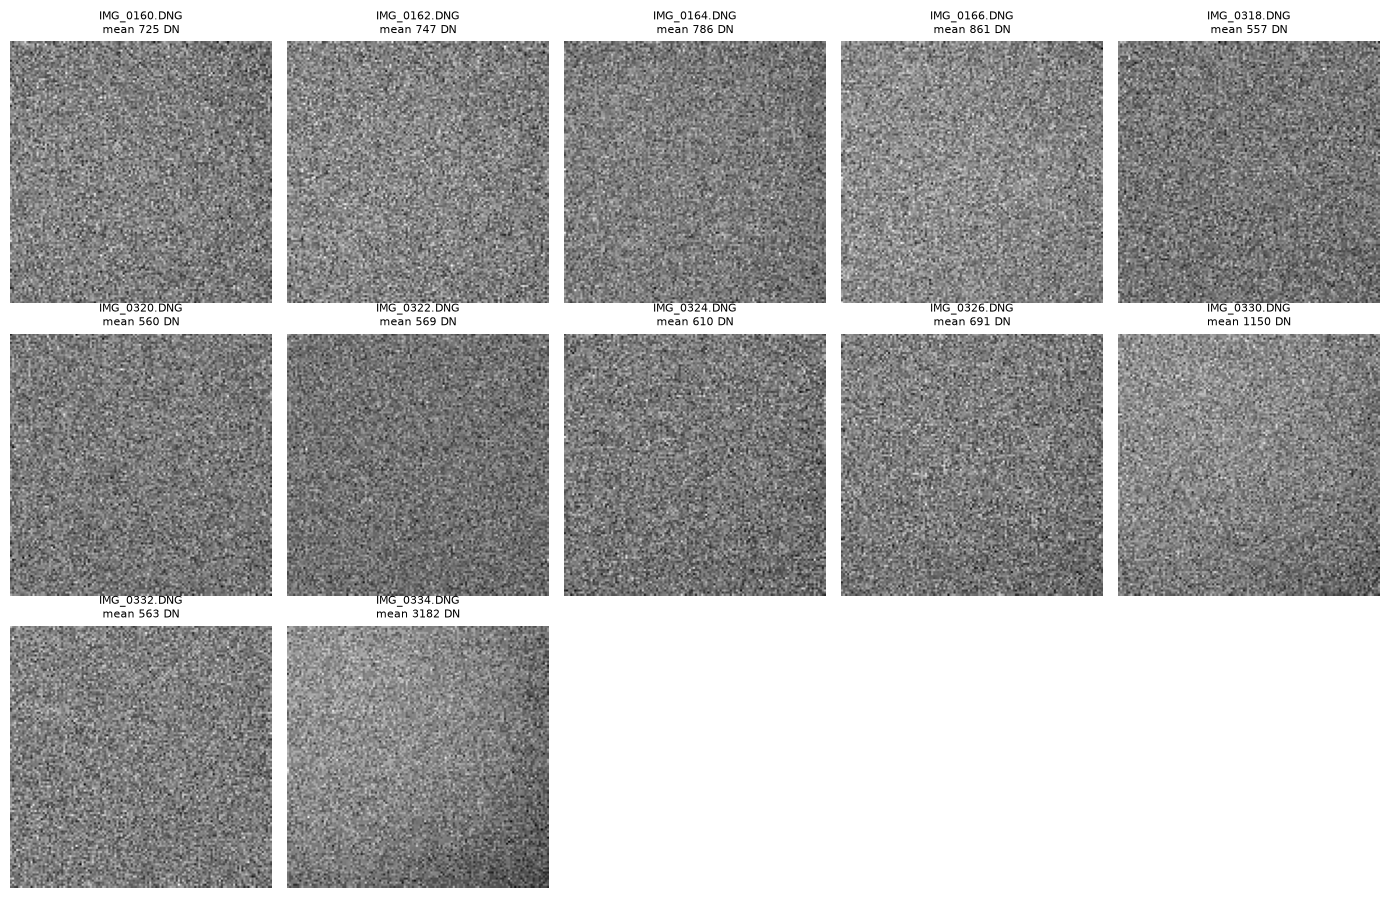

Black level: 528.0, white level: 4095.0
(0.0196078431372549, 32) (0.0196078431372549, 32)
(0.021739130434782608, 32) (0.021739130434782608, 32)
(0.02564102564102564, 32) (0.02564102564102564, 32)
(0.03333333333333333, 32) (0.03333333333333333, 32)
(0.022222222222222223, 32) (0.022222222222222223, 32)
(0.023809523809523808, 32) (0.023809523809523808, 32)
(0.03333333333333333, 32) (0.03333333333333333, 32)
(0.06666666666666667, 32) (0.06666666666666667, 32)
(0.125, 32) (0.125, 32)
(0.5, 32) (0.5, 32)
(0.02857142857142857, 32) (0.02857142857142857, 32)
(1.0, 32) (1.0, 32)
Pair   Exposure   ISO    Mean (DN)   Var (DN^2)   Pixels
1        0.0196    32       196.82        82.75    16384
2        0.0217    32       218.49        90.55    16384
3        0.0256    32       258.25       105.47    16384
4        0.0333    32       332.76       133.59    16384
5        0.0222    32        28.91        14.81    16384
6        0.0238    32        31.68        15.85    16384
7        0.0333    32    

In [9]:
FOLDER = r"C:\Users\ammat\Documents\Assigmnet3 Captures\old"
PATCH = 128
B_level = 527.7
def load_green_plane(path):
    """Return the first green (G1) sub-image of the Bayer mosaic as a 2D float array."""
    with rawpy.imread(str(path)) as raw:
        img = raw.raw_image_visible.astype(np.float64)   # float avoids uint16 wraparound in a - b
        colors = raw.raw_colors_visible
        desc = raw.color_desc.decode()                    # e.g. "RGBG"
    # find the first green site inside the 2x2 Bayer cell
    for r in range(2):
        for c in range(2):
            if desc[colors[r, c]] == "G":
                return img[r::2, c::2]
    raise ValueError("No green pixel found in the 2x2 cell")

def load_center_patch(path, size=PATCH):
    """Center size x size crop of the G1 plane, returned as a 2D array."""
    g = load_green_plane(path)
    rows, cols = g.shape
    r0 = rows // 2 - size // 2
    c0 = cols // 2 - size // 2
    return g[r0:r0 + size, c0:c0 + size]

def show_patches(files, step=2, cols=5):
    """Display the G1 center patch of every `step`-th file (step=2 -> first frame of each pair)."""
    selected = files[::step]
    rows = int(np.ceil(len(selected) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.8, rows * 3), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, p in zip(axes.flat, selected):
        patch = load_center_patch(p)
        ax.imshow(patch, cmap="gray")
        ax.set_title(f"{p.name}\nmean {patch.mean():.0f} DN", fontsize=8)
    plt.tight_layout()
    plt.show()

def PTC_calculations(pairs, black_level=527):
    means, var_pair, n_pixels = [], [], []
    for a, b in pairs:
        means.append((a.mean() + b.mean()) / 2 - black_level)
        var_pair.append(np.var(a - b) / 2)   # differencing cancels fixed-pattern noise
        n_pixels.append(a.size)              # pixels per patch
        
    return means, var_pair, n_pixels

# --- build the pairs ---
files = sorted(p for p in Path(FOLDER).glob("*") if p.suffix.lower() == ".dng")
assert len(files) % 2 == 0, f"Odd number of files ({len(files)}), pairs won't line up"
show_patches(files)
# black/white levels from the files themselves
with rawpy.imread(str(files[0])) as raw:
    BLACK = float(np.mean(raw.black_level_per_channel))
    WHITE = float(raw.white_level)
print(f"Black level: {BLACK}, white level: {WHITE}")

capturePairs, pairSettings = [], []
for f1, f2 in zip(files[0::2], files[1::2]):
    s1, s2 = get_exposure_iso(f1), get_exposure_iso(f2)
    print(get_exposure_iso(f1), get_exposure_iso(f2)) # make sure that the exposure pairs match
    if s1 != s2:
        print(f"WARNING: settings differ for {f1.name} / {f2.name}: {s1} vs {s2}")
        
    a, b = load_center_patch(f1), load_center_patch(f2)
    assert a.shape == b.shape == (PATCH, PATCH), f"Unexpected patch shape for {f1.name}: {a.shape}, {b.shape}"
    capturePairs.append((a, b))
    pairSettings.append(s1)

# --- compute and report ---
means, var_pair, n_pixels = PTC_calculations(capturePairs, black_level=BLACK)

print(f"{'Pair':<5}{'Exposure':>10}{'ISO':>6}{'Mean (DN)':>13}{'Var (DN^2)':>13}{'Pixels':>9}")
for i, ((exp, iso), m, v, n) in enumerate(zip(pairSettings, means, var_pair, n_pixels), 1):
    print(f"{i:<5}{exp:>10.4f}{str(iso):>6}{m:>13.2f}{v:>13.2f}{n:>9}")

6. Fit a line through the points that lie below 70 percent of saturation, and report the conversion gain and the read noise.
Deliverable: A figure of variance against mean showing the fitted line with the excluded points distinguished, the gain in digital numbers per electron, and the read noise in electrons, each with an uncertainty from the fit.

In [10]:
with rawpy.imread(str(files[0])) as raw:
    BLACK = float(np.mean(raw.black_level_per_channel))  # 528 for your files
    WHITE = float(raw.white_level)

print(f"Black level: {BLACK}, white level: {WHITE}")

Black level: 528.0, white level: 4095.0


value for read2.9496994620466594
Points used in fit: 11 of 12 (excluded: 1)
Gain K       = 0.4099 ± 0.0038 DN/e-
Intercept    = 1.46 ± 0.97 DN^2
Read noise   = 2.95 ± 1.00 e-


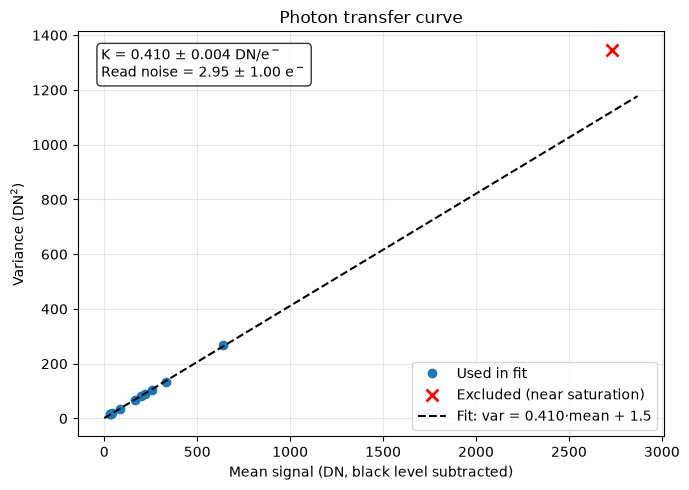

In [11]:
import numpy as np
import matplotlib.pyplot as plt

def fit_ptc(mean, var, frac=0.7): # update to inclide uncertainty measures
    """Fit var = K*mean + b over points below `frac` of saturation. Returns fit, covariance, mask."""
    ok = mean < (4095.0 - 528) * frac
    (slope, intercept), cov = np.polyfit(mean[ok], var[ok], 1, cov=True)
    return slope, intercept, cov, ok

means = np.asarray(means, dtype=float)
var_pair = np.asarray(var_pair, dtype=float)

slope, intercept, cov, ok = fit_ptc(means, var_pair)

# gain K in DN/e-, with 1-sigma uncertainty from the fit
K = slope
sK = np.sqrt(cov[0, 0])
sb = np.sqrt(cov[1, 1])

# read noise in electrons: sqrt(intercept) / K, propagated with the slope-intercept covariance
read = np.sqrt(max(intercept, 0)) / K
#print(read)
print("value for read" + str(read))
if intercept > 0:
    dK = -np.sqrt(intercept) / K**2
    db = 1 / (2 * K * np.sqrt(intercept))
    s_read = np.sqrt(db**2 * sb**2 + dK**2 * sK**2 + 2 * db * dK * cov[0, 1])
else:
    s_read = np.nan  # intercept <= 0: read noise isn't resolvable from this fit

print(f"Points used in fit: {ok.sum()} of {len(ok)} (excluded: {(~ok).sum()})")
print(f"Gain K       = {K:.4f} ± {sK:.4f} DN/e-")
print(f"Intercept    = {intercept:.2f} ± {sb:.2f} DN^2")
print(f"Read noise   = {read:.2f} ± {s_read:.2f} e-")

# figure
x = np.linspace(0, means.max() * 1.05, 200)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(means[ok], var_pair[ok], "o", label="Used in fit")
ax.plot(means[~ok], var_pair[~ok], "x", color="red", ms=9, mew=2, label="Excluded (near saturation)")
ax.plot(x, K * x + intercept, "k--",
        label=f"Fit: var = {K:.3f}·mean + {intercept:.1f}")
ax.set_xlabel("Mean signal (DN, black level subtracted)")
ax.set_ylabel("Variance (DN$^2$)")
ax.set_title("Photon transfer curve")
ax.text(0.04, 0.96,
        f"K = {K:.3f} ± {sK:.3f} DN/e$^-$\nRead noise = {read:.2f} ± {s_read:.2f} e$^-$",
        transform=ax.transAxes, va="top", bbox=dict(boxstyle="round", fc="white", alpha=0.8))
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


7. Repeat the fit using the variance of a single frame at each level in place of the difference of pairs, and report both gains. The two disagree because one quantity present in the photographs is absent from the model. Name that quantity, and say which way it moves the gain and why.
Deliverable: Both gains, their percentage difference, and a written explanation (2 to 3 sentences).

value for read2.9496994620466594


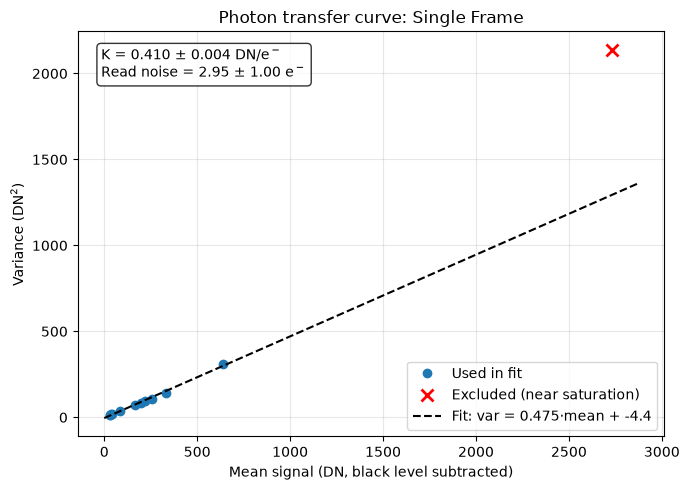

Single Frame Fit Values: 
Gain K       = 0.4752 ± 0.0132 DN/e-
Intercept    = -4.38 ± 3.35 DN^2
Read noise   = 0.00 ± nan e-
Differnce two frames Fit Values: 
Gain K       = 0.4099 ± 0.0038 DN/e-
Intercept    = 1.46 ± 0.97 DN^2
Read noise   = 2.95 ± 1.00 e-
percent difference:
Gain K       = 14.773794264576795  %
Intercept    = -400.5367401333408 %
Read noise   = 200.0  %


In [12]:
def PTC_calculations_single(pairs, black_level=528):
    means, var_pair, n_pixels, var_single = [], [], [], []
    for a, b in pairs:
        means.append((a.mean() + b.mean()) / 2 - black_level)
        var_pair.append(np.var(a - b) / 2)   # differencing cancels fixed-pattern noise
        n_pixels.append(a.size)              # pixels per patch
        var_single.append(a.var())
              
    return means, var_single, n_pixels
means, var_single, n_pixels = PTC_calculations_single(capturePairs, black_level=BLACK)

means = np.asarray(means, dtype=float)
var_single = np.asarray(var_single, dtype=float)

slopeS, interceptS, covS, ok = fit_ptc(means, var_single)

# gain K in DN/e-, with 1-sigma uncertainty from the fit
K_S = slopeS
sK_S = np.sqrt(covS[0, 0])
sb_S = np.sqrt(covS[1, 1])

# read noise in electrons: sqrt(intercept) / K, propagated with the slope-intercept covariance
read_S = np.sqrt(max(interceptS, 0)) / K
#print(read)
print("value for read" + str(read))
if interceptS > 0:
    dK = -np.sqrt(interceptS) / K**2
    db = 1 / (2 * K * np.sqrt(interceptS))
    s_read = np.sqrt(db**2 * sb**2 + dK**2 * sK**2 + 2 * db * dK * covS[0, 1])
else:
    s_readS = np.nan  # intercept <= 0: read noise isn't resolvable from this fit

# figure
x = np.linspace(0, means.max() * 1.05, 200)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(means[ok], var_single[ok], "o", label="Used in fit")
ax.plot(means[~ok], var_single[~ok], "x", color="red", ms=9, mew=2, label="Excluded (near saturation)")
ax.plot(x, K_S * x + interceptS, "k--",
        label=f"Fit: var = {K_S:.3f}·mean + {interceptS:.1f}")
ax.set_xlabel("Mean signal (DN, black level subtracted)")
ax.set_ylabel("Variance (DN$^2$)")
ax.set_title("Photon transfer curve: Single Frame")
ax.text(0.04, 0.96,
        f"K = {K:.3f} ± {sK:.3f} DN/e$^-$\nRead noise = {read:.2f} ± {s_read:.2f} e$^-$",
        transform=ax.transAxes, va="top", bbox=dict(boxstyle="round", fc="white", alpha=0.8))
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


# Read out comparision:
print("Single Frame Fit Values: ")
print(f"Gain K       = {K_S:.4f} ± {sK_S:.4f} DN/e-")
print(f"Intercept    = {interceptS:.2f} ± {sb_S:.2f} DN^2")
print(f"Read noise   = {read_S:.2f} ± {s_readS:.2f} e-")

print("Differnce two frames Fit Values: ")
print(f"Gain K       = {K:.4f} ± {sK:.4f} DN/e-")
print(f"Intercept    = {intercept:.2f} ± {sb:.2f} DN^2")
print(f"Read noise   = {read:.2f} ± {s_read:.2f} e-")

print("percent difference:")
print(f"Gain K       = {(abs(K-K_S)/((K+K_S)*.5)) * 100}  %")
print(f"Intercept    = {(abs(intercept-interceptS)/((intercept+interceptS)*.5)) * 100} %")
print(f"Read noise   = {(abs(read-read_S)/((read+read_S)*.5)) * 100}  %")

The model does not take fixed pattern noise into account. We remove this when we take the difference of two frames because they both contain the same fixed pattern. But if we use only one frame and thus we keep the fixed pattern noise then we will end up with a higher gain because the fixed pattern noise is a multiplicative gain variation.

8. Report your full well capacity in electrons and your dynamic range in stops. More than one convention exists for the low end of the dynamic range, and the number you get depends on which you adopt, so state yours.
Deliverable: Full well in electrons, dynamic range in stops, and the criterion you used.

In [13]:
# step 1 gain
gain = K

# step 2: read noise
readNoise = read

# step 3: saturation level above black
with rawpy.imread(str(files[-1])) as raw:
    clip = raw.raw_image_visible.max()
print(f"Brightest-frame max: {clip}, nominal white level: {WHITE}") # the max value of the frame that is above saturation
sat_DN = clip - BLACK          # or WHITE - BLACK if the frame never clipped

def dr_numbers(K, b, sat_DN):
    read_e = np.sqrt(b) / K                       # step 2
    fw = sat_DN / K                               # step 4
    def floor_at_snr(T):                          # signal where S / sqrt(S + read^2) = T
        return (T**2 + np.sqrt(T**4 + 4 * T**2 * read_e**2)) / 2
    return {
        "full_well_e": fw,
        "read_noise_e": read_e,
        "DR_readnoise_stops": np.log2(fw / read_e),
        "DR_snr1_stops": np.log2(fw / floor_at_snr(1)),
        "DR_snr10_stops": np.log2(fw / floor_at_snr(10)),
    }

nominal = dr_numbers(slope, intercept, sat_DN)

# uncertainties: sample (K, intercept) from the fit covariance
rng = np.random.default_rng(0)
draws = rng.multivariate_normal([slope, intercept], cov, size=20000)
draws = draws[(draws[:, 0] > 0) & (draws[:, 1] > 0)]
spread = dr_numbers(draws[:, 0], draws[:, 1], sat_DN)

for key, val in nominal.items():
    print(f"{key:>20}: {val:9.2f} ± {np.std(spread[key]):.2f}")

Brightest-frame max: 3569, nominal white level: 4095.0
         full_well_e:   7419.76 ± 65.51
        read_noise_e:      2.95 ± 0.92
  DR_readnoise_stops:     11.30 ± 0.58
       DR_snr1_stops:     11.05 ± 0.41
      DR_snr10_stops:      6.10 ± 0.05


The full well value is 7419.76 ± 210.58 e-, this value is max number of e- a pixel can hold without becoming saturated. We get this by first subtracting the black value so we are going from what we would measure with no signal to the 'top'. Then we devide by gain to convert to e-. The dynamic range is 11.05 ± 0.58 stops. This value is the ratio of the largest signal we can measure over the smallest. The defenition of the smallest signal you can measure is where the multiple defintions of this value come from. Here I picked where SNR = 1 as the smallest signal because this will include both read and shot noise. The DR is measred in stops which is log2(), so one stop is doubling. 

### Part 3: Signal to Noise

9. 

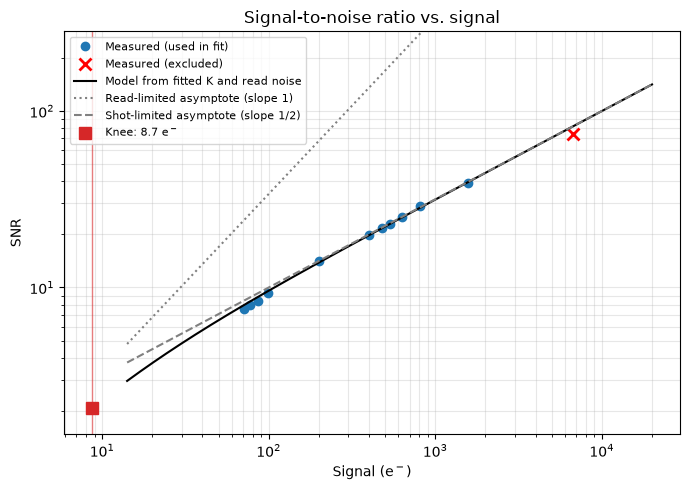

Knee = 8.7 ± 5.3 e-  (read noise = 2.95 e-)
Measured signal range: 70.5 to 6667 e-
Reaches read-limited regime (signal below knee): False
Reaches shot-limited regime (signal above knee): True


In [14]:
import numpy as np
import matplotlib.pyplot as plt

K = slope                                  # DN/e-
read_e = np.sqrt(intercept) / K            # read noise, e-
knee_e = read_e**2                         # signal where shot variance = read variance

# measured data
S_e = means / K                            # signal in electrons
snr = means / np.sqrt(var_pair)            # unitless, so same in DN or e-

# model: SNR = S / sqrt(S + r^2)
S_model = np.logspace(np.log10(S_e.min() / 5), np.log10(S_e.max() * 3), 400)
snr_model = S_model / np.sqrt(S_model + read_e**2)
knee_snr = knee_e / np.sqrt(knee_e + read_e**2)

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(S_e[ok], snr[ok], "o", label="Measured (used in fit)")
if (~ok).any():
    ax.loglog(S_e[~ok], snr[~ok], "x", color="red", ms=9, mew=2, label="Measured (excluded)")
ax.loglog(S_model, snr_model, "k-", label="Model from fitted K and read noise")
ax.loglog(S_model, S_model / read_e, ":", color="gray", label="Read-limited asymptote (slope 1)")
ax.loglog(S_model, np.sqrt(S_model), "--", color="gray", label="Shot-limited asymptote (slope 1/2)")
ax.axvline(knee_e, color="C3", lw=1, alpha=0.6)
ax.plot(knee_e, knee_snr, "s", color="C3", ms=9, label=f"Knee: {knee_e:.1f} e$^-$")
ax.set_xlabel("Signal (e$^-$)")
ax.set_ylabel("SNR")
ax.set_title("Signal-to-noise ratio vs. signal")
ax.set_ylim(snr_model.min() / 2, snr_model.max() * 2)
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

# knee uncertainty from the fit covariance
rng = np.random.default_rng(0)
d = rng.multivariate_normal([slope, intercept], cov, size=20000)
d = d[(d[:, 0] > 0) & (d[:, 1] > 0)]
knee_draws = d[:, 1] / d[:, 0]**2
print(f"Knee = {knee_e:.1f} ± {knee_draws.std():.1f} e-  (read noise = {read_e:.2f} e-)")

# do the captures reach both regimes?
print(f"Measured signal range: {S_e.min():.1f} to {S_e.max():.0f} e-")
print("Reaches read-limited regime (signal below knee):", S_e.min() < knee_e)
print("Reaches shot-limited regime (signal above knee):", S_e.max() > knee_e)

The kneee is at 8.7 e-. All my points are above that in the plot shown above. This means that we are exclusivly in the shot noise limited regime (my captures do not reah into both regimes). 

10 . Check whether your DNG carries a NoiseProfile tag, which is the manufacturer's own noise model. If it is present, convert it into a gain and a read noise that can be compared against yours; the tag is written in units of normalized signal, so the conversion is a matter of carrying the white level minus the black level through the model.
Deliverable: The vendor figures beside your own, or a statement that the tag is absent.

In [23]:
import tifffile

def get_noise_profile_tifffile(path):
    with tifffile.TiffFile(path) as tif:
        stack = list(tif.pages)
        while stack:
            page = stack.pop()
            tag = page.tags.get(51041)           # NoiseProfile
            if tag is not None:
                return list(tag.value)
            sub = getattr(page, "pages", None)   # SubIFDs, if this tifffile version exposes them
            if sub is not None:
                stack.extend(list(sub))
    return None

get_noise_profile_tifffile(files[10]) #<- this gives you the intercept and slope of the manufacture noise profile

[2.8413910420900002e-05, 2.42434125376e-07]

In [25]:
# convert using our white level - dark level (it is currently noramlized to 0-1)
profile = get_noise_profile_tifffile(files[10])
S, O = profile[0], profile[1]            # first plane; compare the other planes too
rng_dn = WHITE - BLACK

K_equiv = rng_dn * S                      # variance slope in DN^2 per DN, i.e. gain K
b_equiv = rng_dn**2 * O                   # intercept in DN^2
read_e_equiv = np.sqrt(b_equiv) / K_equiv

print(f"Manufacturer model: K = {K_equiv:.4f} DN/e-, intercept = {b_equiv:.2f} DN^2, "
      f"read noise = {read_e_equiv:.2f} e-")
print(f"My fit:           K = {slope:.4f} DN/e-, intercept = {intercept:.2f} DN^2, "
      f"read noise = {np.sqrt(intercept)/slope:.2f} e-")

Manufacturer model: K = 0.1014 DN/e-, intercept = 3.08 DN^2, read noise = 17.33 e-
My fit:           K = 0.4099 DN/e-, intercept = 1.46 DN^2, read noise = 2.95 e-


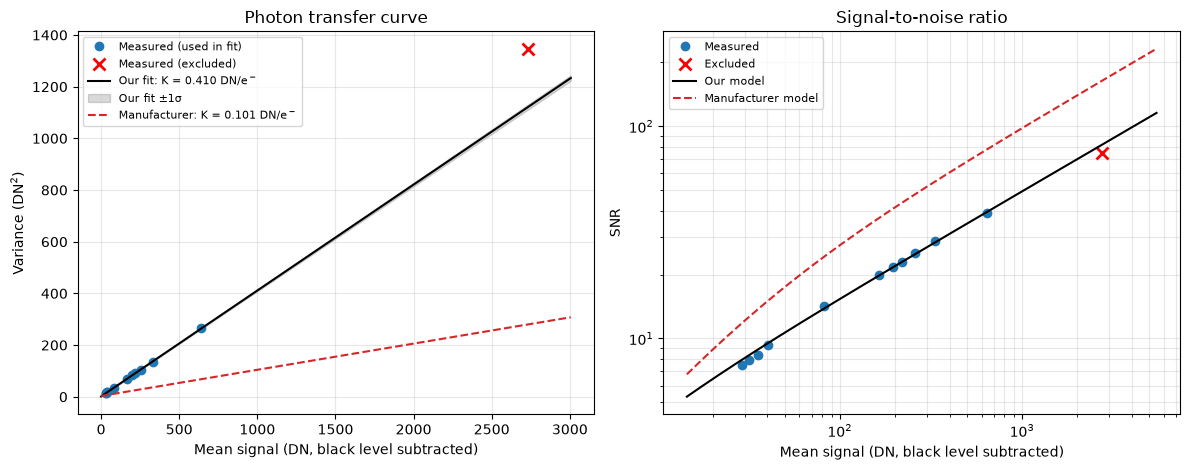

                 K (DN/e-)    Intercept (DN^2)   Read noise (e-)
My fit              0.4099                1.46              2.95
Manufacturer        0.1014                3.08             17.33


In [26]:
#figure to compare the two curves

# --- manufacturer model, converted to DN units ---
S_mfr, O_mfr = get_noise_profile_tifffile(files[0])
with rawpy.imread(str(files[0])) as raw:
    white_tag = float(raw.white_level)      # use the file's WhiteLevel tag, not your observed clip level
rng_dn = white_tag - BLACK
K_mfr = rng_dn * S_mfr                      # DN/e-
b_mfr = rng_dn**2 * O_mfr                   # DN^2

# --- evaluate both models ---
x = np.linspace(0, means.max() * 1.1, 300)
var_fit = slope * x + intercept
band = np.sqrt(x**2 * cov[0, 0] + 2 * x * cov[0, 1] + cov[1, 1])   # 1-sigma uncertainty of the fitted line
var_mfr = K_mfr * x + b_mfr

xl = np.logspace(np.log10(means.min() / 2), np.log10(means.max() * 2), 300)
snr_fit = xl / np.sqrt(np.maximum(slope * xl + intercept, 1e-12))
snr_mfr = xl / np.sqrt(K_mfr * xl + b_mfr)
snr_data = means / np.sqrt(var_pair)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# left: photon transfer curve
ax1.plot(means[ok], var_pair[ok], "o", label="Measured (used in fit)")
if (~ok).any():
    ax1.plot(means[~ok], var_pair[~ok], "x", color="red", ms=9, mew=2, label="Measured (excluded)")
ax1.plot(x, var_fit, "k-", label=f"Our fit: K = {slope:.3f} DN/e$^-$")
ax1.fill_between(x, var_fit - band, var_fit + band, color="k", alpha=0.15, label="Our fit ±1σ")
ax1.plot(x, var_mfr, "C3--", label=f"Manufacturer: K = {K_mfr:.3f} DN/e$^-$")
ax1.set_xlabel("Mean signal (DN, black level subtracted)")
ax1.set_ylabel("Variance (DN$^2$)")
ax1.set_title("Photon transfer curve")
ax1.grid(alpha=0.3); ax1.legend(fontsize=8)

# right: SNR vs signal (unitless, so it's the same in DN or e-)
ax2.loglog(means[ok], snr_data[ok], "o", label="Measured")
if (~ok).any():
    ax2.loglog(means[~ok], snr_data[~ok], "x", color="red", ms=9, mew=2, label="Excluded")
ax2.loglog(xl, snr_fit, "k-", label="Our model")
ax2.loglog(xl, snr_mfr, "C3--", label="Manufacturer model")
ax2.set_xlabel("Mean signal (DN, black level subtracted)")
ax2.set_ylabel("SNR")
ax2.set_title("Signal-to-noise ratio")
ax2.grid(alpha=0.3, which="both"); ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

# --- numbers side by side ---
print(f"{'':<14}{'K (DN/e-)':>12}{'Intercept (DN^2)':>20}{'Read noise (e-)':>18}")
print(f"{'My fit':<14}{slope:>12.4f}{intercept:>20.2f}{np.sqrt(max(intercept, 0)) / slope:>18.2f}")
print(f"{'Manufacturer':<14}{K_mfr:>12.4f}{b_mfr:>20.2f}{np.sqrt(b_mfr) / K_mfr:>18.2f}")

Our model and the manufacturer results are very different. However, because we meaured ours directly on the raw captures I will use ours. For theirs we have to assumes it is for the same iso settings as we did but I do not see a way to confirm, we also do not know what other assumptions were used on theirs, we also can not get an uncertianty value for their fit. We also (as far as I know) do not know if they do other processing on the images to calculate the manufacture curve, we are just using the raw files which should be the correct approach. 

### Dark Current

11. Fit the dark current from the capped frames you took in item 3 by plotting their mean against exposure time and converting the slope to electrons per second with your gain. Dark current roughly doubles for every 6 to 8 degrees Celsius, so note whether the phone was warm. If your longest available exposure is only a fraction of a second, the result may be indistinguishable from zero, and in that case an upper bound with an argument behind it is the correct answer.
Deliverable: The figure, and the dark current in electrons per second with an uncertainty, or a defended upper bound.

Frames: 4 at 4 exposure times
Slope     = 0.2504 ± 0.0464 DN/s
Intercept = 527.66 ± 0.01 DN  (file black level: 528.0)
Dark current = 0.611 ± 0.113 e-/s  (using K = 0.4099 DN/e-)


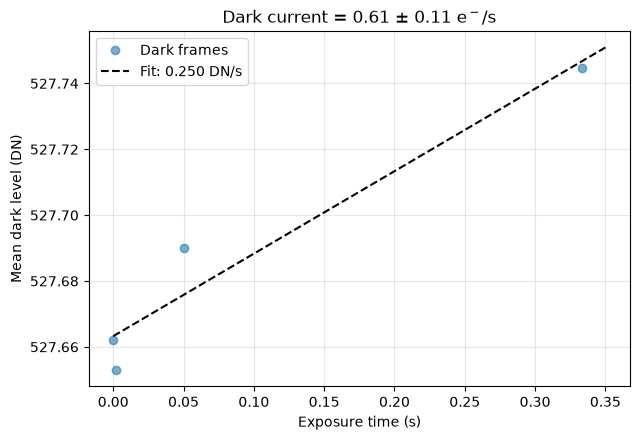

In [30]:
# folder with the dark frames is where?
FOLDER_Dark = r"C:\Users\ammat\Documents\Assigmnet3 Captures\BlackFrame"

def dark_current_fit(folder, K, sK, black_level=None):
    """Fit mean dark level vs exposure time; convert slope (DN/s) to e-/s using gain K (DN/e-)."""
    files = sorted(p for p in Path(folder).glob("*") if p.suffix.lower() == ".dng")

    t, m = [], []
    for p in files:
        exposure, iso = get_exposure_iso(p)
        t.append(float(Fraction(exposure)))          # '1/120' -> seconds
        m.append(load_green_plane(p).mean())         # whole G1 plane: more pixels, tighter mean
    t, m = np.array(t), np.array(m)

    (slope_dn, icpt), cov = np.polyfit(t, m, 1, cov=True)
    s_slope = np.sqrt(cov[0, 0])

    dc = slope_dn / K                                # e-/s
    s_dc = abs(dc) * np.sqrt((s_slope / slope_dn)**2 + (sK / K)**2) if slope_dn != 0 else np.nan

    print(f"Frames: {len(t)} at {len(np.unique(t))} exposure times")
    print(f"Slope     = {slope_dn:.4f} ± {s_slope:.4f} DN/s")
    print(f"Intercept = {icpt:.2f} ± {np.sqrt(cov[1, 1]):.2f} DN" +
          (f"  (file black level: {black_level})" if black_level is not None else ""))
    print(f"Dark current = {dc:.3f} ± {s_dc:.3f} e-/s  (using K = {K:.4f} DN/e-)")
    if abs(slope_dn) < 2 * s_slope:
        print(f"Slope is within 2σ of zero: report an upper bound of about {(slope_dn + 2 * s_slope) / K:.3f} e-/s")

    # figure
    xs = np.linspace(0, t.max() * 1.05, 100)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(t, m, "o", alpha=0.6, label="Dark frames")
    ax.plot(xs, slope_dn * xs + icpt, "k--", label=f"Fit: {slope_dn:.3f} DN/s")
    ax.set_xlabel("Exposure time (s)")
    ax.set_ylabel("Mean dark level (DN)")
    ax.set_title(f"Dark current = {dc:.2f} ± {s_dc:.2f} e$^-$/s")
    ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.show()
    return dc, s_dc

dc, s_dc = dark_current_fit(FOLDER_Dark, K=slope, sK=np.sqrt(cov[0, 0]), black_level=BLACK)



Dark Current with uncertainty = Dark current = 0.611 ± 0.113 e-/s.

### Part 5: Linear Light

12. Construct a checkerboard of pure black and pure white pixels, exactly half of each, and compute its mean twice: once by averaging the sRGB-encoded values directly, and once by linearizing, averaging, and re-encoding.
Deliverable: Both values, and one sentence identifying which of them is the brightness a camera pointed at that checkerboard would have recorded.

Direct average of encoded values:   0.5000  (127.5 / 255)
Average in linear light:            0.5000
Linear average re-encoded to sRGB:  0.7354  (187.5 / 255)


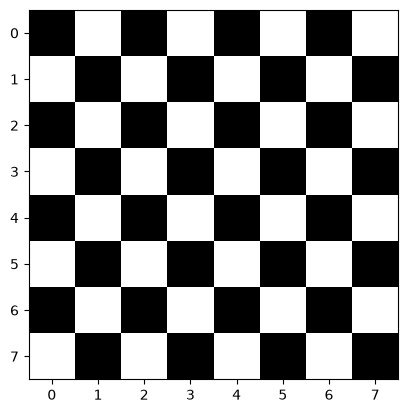

In [33]:
import numpy as np

def srgb_to_linear(c):
    """sRGB-encoded values in [0, 1] -> linear light."""
    c = np.asarray(c, dtype=float)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)

def linear_to_srgb(l):
    """Linear light in [0, 1] -> sRGB-encoded values."""
    l = np.asarray(l, dtype=float)
    return np.where(l <= 0.0031308, 12.92 * l, 1.055 * np.power(l, 1 / 2.4) - 0.055)

# checkerboard of pure black (0) and pure white (1), exactly half of each
N = 8                                          # must be even so the halves are exact
rows, cols = np.indices((N, N))
board = ((rows + cols) % 2).astype(float)
assert board.mean() == 0.5                     # confirms exactly half white
plt.imshow(board,cmap='gray')
# 1) average the encoded values directly
mean_encoded = board.mean()

# 2) linearize, average, re-encode
mean_linear = srgb_to_linear(board).mean()
mean_reencoded = float(linear_to_srgb(mean_linear))

print(f"Direct average of encoded values:   {mean_encoded:.4f}  ({mean_encoded * 255:.1f} / 255)")
print(f"Average in linear light:            {mean_linear:.4f}")
print(f"Linear average re-encoded to sRGB:  {mean_reencoded:.4f}  ({mean_reencoded * 255:.1f} / 255)")

which value does a camera measure dirrectly? I believe that the camera records the one that has been linearized and then averaged because the camera measured linear light. 

13. Do the same thing to real data. Take one of your checkerboard calibration captures from Exercise 1, extract a green plane, encode it to sRGB, and then reduce it by a factor of eight two ways: by averaging the encoded values, and by averaging in linear light and encoding afterward.
Deliverable: The two reduced images and their difference, the mean absolute difference in 8-bit levels, and one sentence on where in the image the error concentrates.

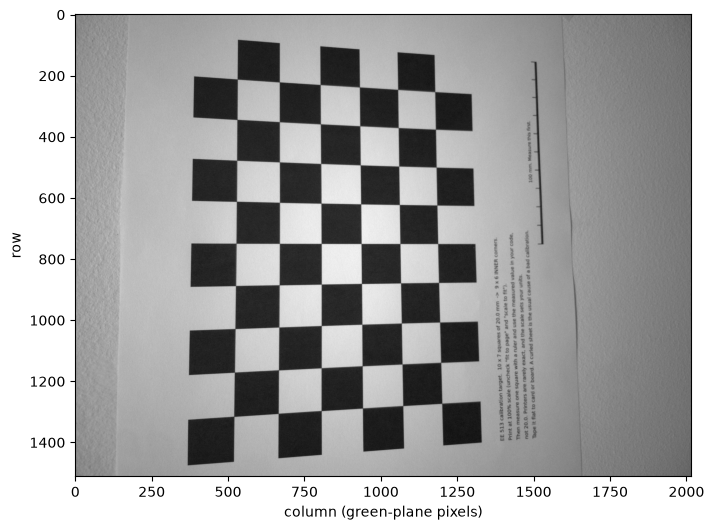

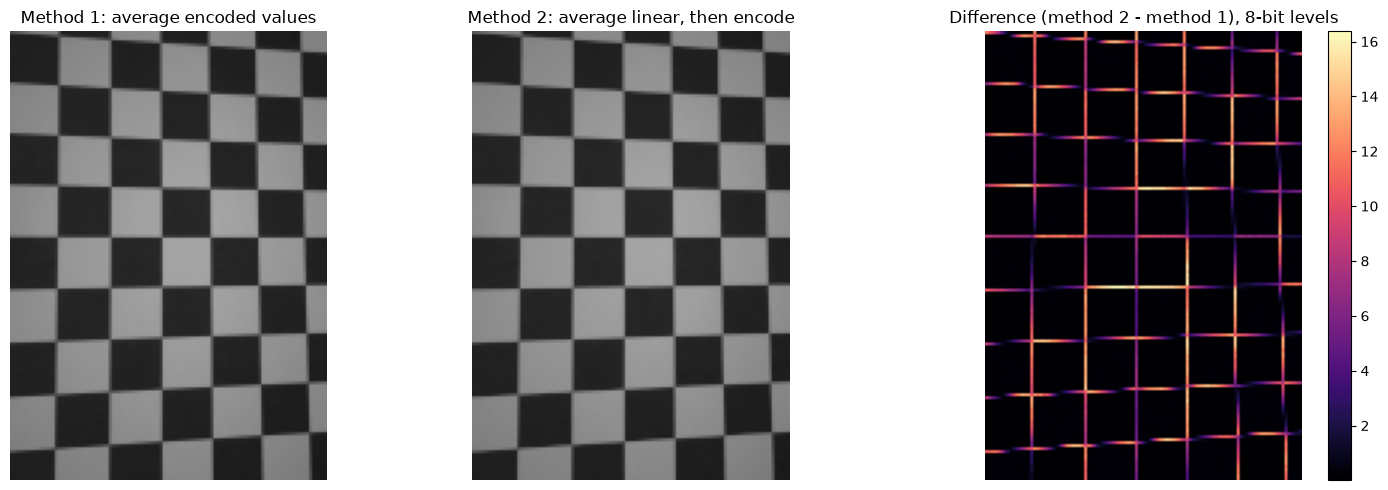

Mean absolute difference: 1.05 


In [42]:
FOLDER_checker = r"C:\Users\ammat\Documents\Assigmnet3 Captures\CheckerBoards"
import numpy as np
import rawpy
import matplotlib.pyplot as plt

Checker_img = r"C:\Users\ammat\Documents\Assigmnet3 Captures\CheckerBoards\Target2.DNG"

def srgb_to_linear(c):
    c = np.asarray(c, dtype=float)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)

def linear_to_srgb(l):
    l = np.asarray(l, dtype=float)
    return np.where(l <= 0.0031308, 12.92 * l, 1.055 * np.power(l, 1 / 2.4) - 0.055)

def block_average(img, n):
    """Average non-overlapping n x n blocks (trims edges that don't fill a block)."""
    h, w = (img.shape[0] // n) * n, (img.shape[1] // n) * n
    return img[:h, :w].reshape(h // n, n, w // n, n).mean(axis=(1, 3))

# --- load the raw file -> extract the green plane (linear, scaled to 0..1) ---
green = load_green_plane(Checker_img)                 # from earlier; first green site, DN
with rawpy.imread(Checker_img) as raw:
    black = float(np.mean(raw.black_level_per_channel))
    white = float(raw.white_level)
linear_full = np.clip((green - black) / (white - black), 0, 1)

# --- crop down to the checkerboard ---
# Step 1: run this and read the row/col of the board's corners off the axes
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(linear_full** (1 / 2.2), cmap="gray")      # quick gamma just so it's visible
ax.set_xlabel("column (green-plane pixels)"); ax.set_ylabel("row")
plt.show()

# Step 2: fill these in from what you read off the axes
r0, r1 = 200, 1400       
c0, c1 = 400, 1250       
linear = linear_full[r0:r1, c0:c1]

# --- encode it to sRGB ---
encoded = linear_to_srgb(linear)

# --- reduce each way ---
N = 8   
# method 1: average the encoded values
m1 = block_average(encoded, N)

# method 2: average in linear light, then encode
m2 = linear_to_srgb(block_average(linear, N))

# --- display the two reduced images and their difference ---
diff = m2 - m1
mad_8bit = np.abs(diff).mean() * 255

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(m1, cmap="gray", vmin=0, vmax=1); axs[0].set_title("Method 1: average encoded values")
axs[1].imshow(m2, cmap="gray", vmin=0, vmax=1); axs[1].set_title("Method 2: average linear, then encode")
im = axs[2].imshow(diff * 255, cmap="magma"); axs[2].set_title("Difference (method 2 - method 1), 8-bit levels")
fig.colorbar(im, ax=axs[2], fraction=0.046)
for a in axs:
    a.axis("off")
plt.tight_layout(); plt.show()

print(f"Mean absolute difference: {mad_8bit:.2f} ")

The differences seem to be along the edges of the squares. I think this makes sense as this is where there are both light and dark parts so it would effect the averaging, while when you have uniform dark or light you will not see a difference with the averaging.

### Reflections: 

14. I learned that you can measure the noise in the camera experimentally by measuring the phototransfer curve. I also learned about the different sources of noise in a camera. I leanred about how we can remove fixed pattern noise by aquiring the difference of two frames. I think this discussion of sources of noise will relavent to understanding any imaging we do in the lab I work in.

15. Maybe more about how to deal with noise in images. From the slides: "Two regimes. Below the knee, fix the electronics. Above it, collect more light" and for fixed pattern noise we need to calibrate it. But I'm sure its more complicated and are there ways to get useful inforation from noisy images? I know averaging was discussed in the lecture but I think I'm not super confident on understanding this. 

AI use:

Similar to the last two assignments I used caude healvily to help with writing python code. Two new things I notice, are 1. I can use it to help explain definitions and processes to bettwe understand what is happinging in the course sides and relate that to the assignment, of course this probably should serve as a jumping off point to then go to human made sources (like class text book). 2. it is helpful in making nice figures, I do not remember most of the matplot lib comands, so this is faster than always looking up how to make the figure nice. 

For all of this it is important to understnad what the output means and this is where comparing what we learned in class to the output of any code or fugures genrated by ai and thinking about what that output means is always important. 